# Detección de violencia en imágenes
## Parte 1. Comprensión y preparación de los datos

- Entrenamiento y validación: *Violence vs. Non-Violence: 11K Images*, fotogramas de los videos de *Real Life Violence Situations*.
- Prueba: dataset de Bianculli et al.

Como las imágenes vienen de videos, una partición aleatoria deja fotogramas del mismo video en entrenamiento y validación. Por eso agrupamos las imágenes por similitud antes de hacer la partición.

## 1. Configuración

In [32]:
import os
import sys
import glob
import shutil
import subprocess
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import cv2
import tensorflow as tf
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from tqdm.auto import tqdm

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASES = ["non_violence", "violence"]
TAM_ENTRADA = 224                     # resolución de entrada de MobileNetV2

# Los archivos generados (embeddings, splits.csv, fotogramas de prueba) se guardan en Google Drive
# para no recalcularlos en cada sesión de Colab. Fuera de Colab se usa la carpeta actual.
USAR_DRIVE = True
if USAR_DRIVE and "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    SALIDA = "/content/drive/MyDrive/violence-detection"
else:
    SALIDA = "."
os.makedirs(SALIDA, exist_ok=True)

EXT_REPO = "/content/bianculli"       # conjunto de prueba [5]
FRAMES_DIR = "/content/bianculli_frames"
print("Salida:", os.path.abspath(SALIDA))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Salida: /content/drive/MyDrive/violence-detection


## 2. Obtención de los datos

Descargamos el dataset de Kaggle con `kagglehub`.

In [33]:
# !pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download("abdulmananraja/real-life-violence-situations")
DATA_DIR = os.path.join(path, "new_violence")
print(DATA_DIR)

Using Colab cache for faster access to the 'real-life-violence-situations' dataset.
/kaggle/input/real-life-violence-situations/new_violence


## 3. Descripción del conjunto

In [34]:
for raiz, carpetas, archivos in os.walk(path):
    nivel = raiz.replace(path, "").count(os.sep)
    print("  " * nivel + os.path.basename(raiz) + f"/  ({len(archivos)} archivos)")

assert sorted(os.listdir(DATA_DIR)) == CLASES

corruptas = []
resumen = []
for clase in CLASES:
    carpeta = os.path.join(DATA_DIR, clase)
    archivos = os.listdir(carpeta)
    extensiones = Counter(os.path.splitext(f)[1].lower() for f in archivos)
    tamanos, modos = Counter(), Counter()
    for f in archivos:
        try:
            with Image.open(os.path.join(carpeta, f)) as im:
                im.verify()
            with Image.open(os.path.join(carpeta, f)) as im:
                tamanos[im.size] += 1
                modos[im.mode] += 1
        except Exception as e:
            corruptas.append((clase, f, str(e)))
    resumen.append({"clase": clase, "imagenes": len(archivos),
                    "extensiones": dict(extensiones), "tamanos": dict(tamanos),
                    "modos": dict(modos), "ejemplos": sorted(archivos)[:6]})

display(pd.DataFrame(resumen).set_index("clase"))
print("Imágenes corruptas:", len(corruptas))

real-life-violence-situations/  (0 archivos)
  new_violence/  (0 archivos)
    non_violence/  (5231 archivos)
    violence/  (5842 archivos)


,imagenes,extensiones,tamanos,modos,ejemplos
clase,,,,,
non_violence,5231,{'.jpg': 5231},"{(416, 416): 5231}",{'RGB': 5231},"[0.jpg, 1.jpg, 10.jpg, 100.jpg, 1000.jpg, 1001..."
violence,5842,{'.jpg': 5842},"{(416, 416): 5842}",{'RGB': 5842},"[0.jpg, 1.jpg, 10.jpg, 100.jpg, 1000.jpg, 1001..."


Imágenes corruptas: 0


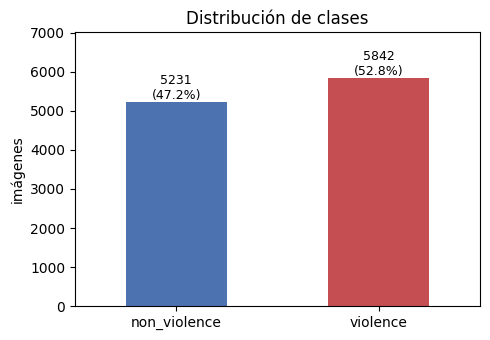

In [35]:
conteo = pd.Series({r["clase"]: r["imagenes"] for r in resumen})
ax = conteo.plot.bar(color=["#4C72B0", "#C44E52"], rot=0, figsize=(5, 3.5))
for i, v in enumerate(conteo):
    ax.text(i, v, f"{v}\n({v / conteo.sum():.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("imágenes")
ax.set_ylim(0, conteo.max() * 1.2)
ax.set_title("Distribución de clases")
plt.tight_layout()
plt.show()

**Observaciones**

- 5,231 imágenes `non_violence` (47.2 %) y 5,842 `violence` (52.8 %).
- Todas son JPEG de 416 × 416 en RGB y ninguna está corrupta.
- Los nombres son índices que se repiten entre clases y no indican de qué video viene cada imagen.

## 4. Inspección visual y orden de los archivos

Revisamos si las imágenes con índices consecutivos pertenecen al mismo video.

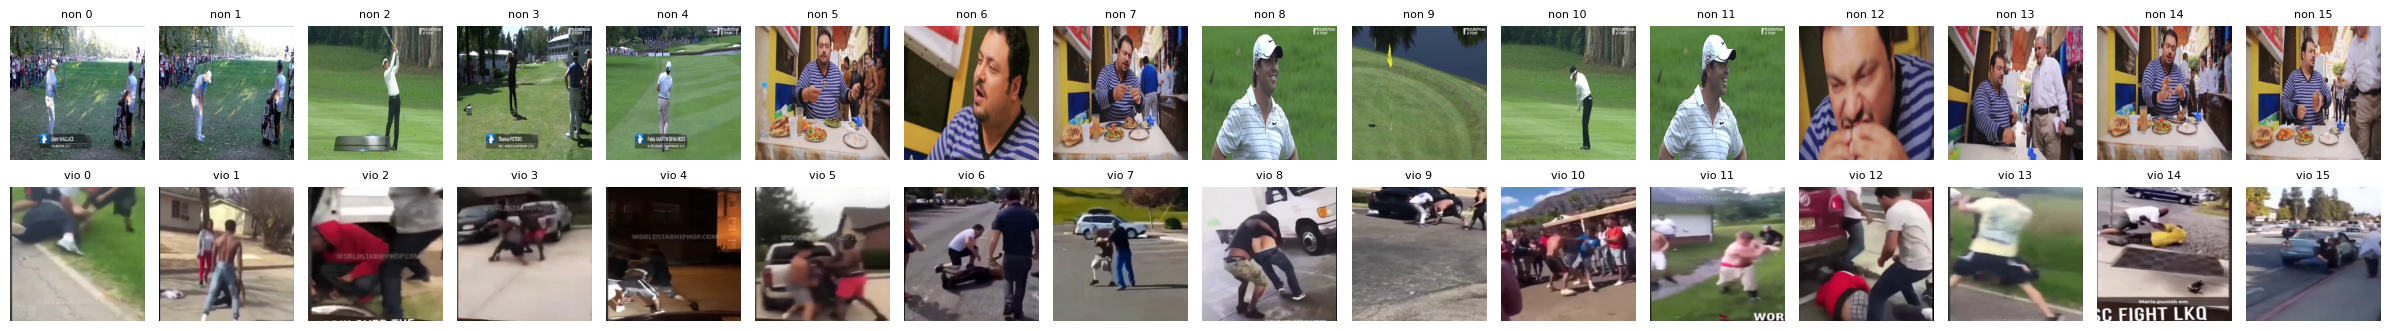

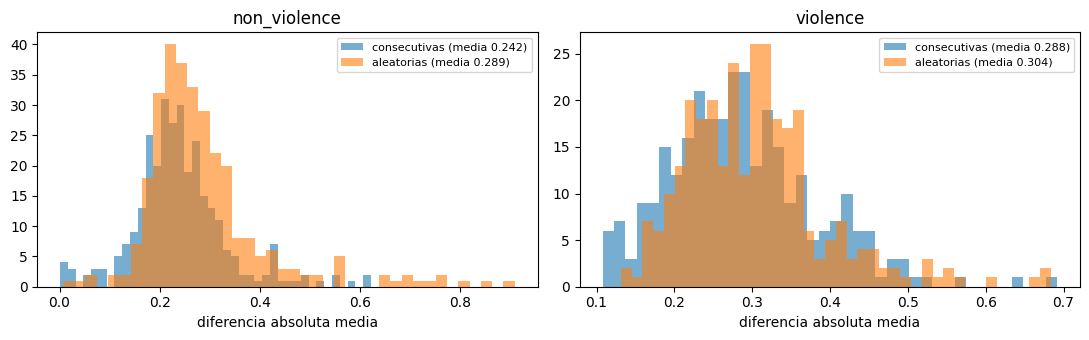

In [36]:
def cargar_gris(clase, idx, lado=64):
    im = Image.open(os.path.join(DATA_DIR, clase, f"{idx}.jpg")).convert("L").resize((lado, lado))
    return np.asarray(im, dtype=np.float32) / 255.0

fig, axes = plt.subplots(2, 16, figsize=(24, 3.5))
for r, clase in enumerate(CLASES):
    for i in range(16):
        axes[r, i].imshow(Image.open(os.path.join(DATA_DIR, clase, f"{i}.jpg")))
        axes[r, i].set_title(f"{clase[:3]} {i}", fontsize=8)
        axes[r, i].axis("off")
plt.tight_layout()
plt.show()

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, clase in zip(axes, CLASES):
    n = len(os.listdir(os.path.join(DATA_DIR, clase)))
    idxs = rng.choice(n - 1, 300, replace=False)
    consecutivas = [np.abs(cargar_gris(clase, i) - cargar_gris(clase, i + 1)).mean() for i in idxs]
    aleatorias = [np.abs(cargar_gris(clase, i) - cargar_gris(clase, j)).mean()
                  for i, j in zip(idxs, rng.choice(n, 300))]
    ax.hist(consecutivas, bins=40, alpha=0.6, label=f"consecutivas (media {np.mean(consecutivas):.3f})")
    ax.hist(aleatorias, bins=40, alpha=0.6, label=f"aleatorias (media {np.mean(aleatorias):.3f})")
    ax.set_title(clase)
    ax.set_xlabel("diferencia absoluta media")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Observaciones**

- La diferencia de píxeles entre imágenes consecutivas es casi igual a la de pares aleatorios.
- Visualmente, una misma escena aparece en índices cercanos pero no contiguos, así que no sirve partir al azar ni por bloques.

## 5. Representación de las imágenes mediante embeddings

Usamos MobileNetV2 preentrenada en ImageNet como extractor de características. Cada imagen queda como un vector de 1,280 dimensiones normalizado con L2, para comparar imágenes con similitud coseno.

In [37]:
registros = []
for clase in CLASES:
    archivos = sorted(os.listdir(os.path.join(DATA_DIR, clase)), key=lambda f: int(f.split(".")[0]))
    registros += [{"ruta": os.path.join(DATA_DIR, clase, f), "clase": clase, "archivo": f"{clase}/{f}"}
                  for f in archivos]
df = pd.DataFrame(registros)

extractor = tf.keras.applications.MobileNetV2(include_top=False, pooling="avg",
                                              input_shape=(TAM_ENTRADA, TAM_ENTRADA, 3),
                                              weights="imagenet")

def leer_imagen(ruta):
    img = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    img = tf.image.resize(img, (TAM_ENTRADA, TAM_ENTRADA))
    return tf.keras.applications.mobilenet_v2.preprocess_input(img)

def calcular_embeddings(rutas, batch=128):
    ds = (tf.data.Dataset.from_tensor_slices(rutas)
          .map(leer_imagen, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(batch)
          .prefetch(tf.data.AUTOTUNE))
    emb = extractor.predict(ds, verbose=1)
    return emb / np.linalg.norm(emb, axis=1, keepdims=True)

ruta_emb = os.path.join(SALIDA, "emb_mobilenetv2.npy")
if os.path.exists(ruta_emb):
    EMB = np.load(ruta_emb)
else:
    EMB = calcular_embeddings(df["ruta"].tolist())
    np.save(ruta_emb, EMB)

assert len(EMB) == len(df)
print("Embeddings:", EMB.shape)

Embeddings: (11073, 1280)


### Verificación por vecino más cercano

Para revisar una partición, buscamos el vecino más cercano en entrenamiento de cada imagen de validación y revisamos visualmente los pares más similares [3].

In [38]:
def vecinos_mas_cercanos(idx_eval, idx_ref):
    sim = EMB[idx_eval] @ EMB[idx_ref].T
    return sim.argmax(1), sim.max(1)

def mostrar_pares(idx_eval, idx_ref, n=16, titulo="", etiqueta="eval"):
    idx_eval, idx_ref = np.asarray(idx_eval), np.asarray(idx_ref)
    vecino, sim_max = vecinos_mas_cercanos(idx_eval, idx_ref)
    print(f"{titulo}: similitud máxima media {sim_max.mean():.3f} | máxima {sim_max.max():.3f}")
    orden = np.argsort(-sim_max)[:n]
    filas = int(np.ceil(n / 8))
    fig, axes = plt.subplots(2 * filas, 8, figsize=(18, 4.6 * filas))
    for k, i in enumerate(orden):
        r, c = 2 * (k // 8), k % 8
        axes[r, c].imshow(Image.open(df.iloc[idx_eval[i]]["ruta"]))
        axes[r, c].set_title(f"#{k + 1} {etiqueta} {sim_max[i]:.2f}", fontsize=8)
        axes[r + 1, c].imshow(Image.open(df.iloc[idx_ref[vecino[i]]]["ruta"]))
        axes[r + 1, c].set_title("train", fontsize=8)
    for a in axes.ravel():
        a.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()
    return sim_max

## 6. Primer intento de agrupación: k-means

Agrupamos los embeddings con k-means, como en SemDeDup, con k = 300 por clase.

count    600.0
mean      18.5
std       10.2
min        2.0
25%       11.0
50%       16.0
75%       24.0
max       67.0
Name: count, dtype: float64
k-means: prueba vs. entrenamiento: similitud máxima media 0.717 | máxima 0.929


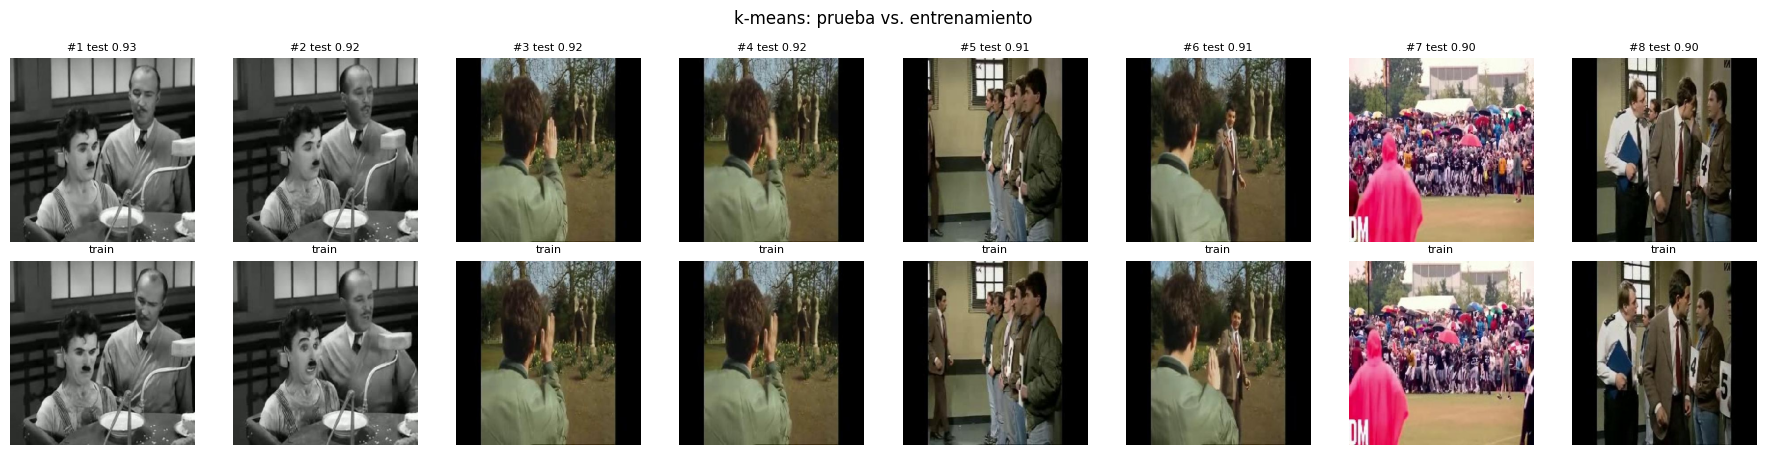

Pares con similitud > 0.95: 0 de 1555


In [ ]:
K = 300
df["grupo_kmeans"] = ""
for clase in CLASES:
    m = (df["clase"] == clase).values
    etiquetas = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit_predict(EMB[m])
    df.loc[m, "grupo_kmeans"] = [f"{clase}_{e}" for e in etiquetas]

print(df["grupo_kmeans"].value_counts().describe().round(1))

gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
idx_train_km, idx_resto = next(gss.split(df, groups=df["grupo_kmeans"]))
gss = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
_, i_test = next(gss.split(df.iloc[idx_resto], groups=df.iloc[idx_resto]["grupo_kmeans"]))
idx_test_km = idx_resto[i_test]

sim_km = mostrar_pares(idx_test_km, idx_train_km, n=8, titulo="k-means: prueba vs. entrenamiento", etiqueta="test")
print("Pares con similitud > 0.95:", (sim_km > 0.95).sum(), "de", len(idx_test_km))

**Resultado**

Los pares más similares (0.90–0.93) siguen siendo del mismo video: k-means separa fotogramas de un mismo video en clusters distintos.

## 7. Limpieza de fotogramas no informativos

Eliminamos los duplicados entre clases (similitud ≥ 0.95) y los fotogramas oscuros (brillo medio < 15). Los duplicados resultaron ser fotogramas negros. En total se eliminaron 58 imágenes y quedaron 11,015.

Pares duplicados entre clases: 15 | imágenes involucradas: 18


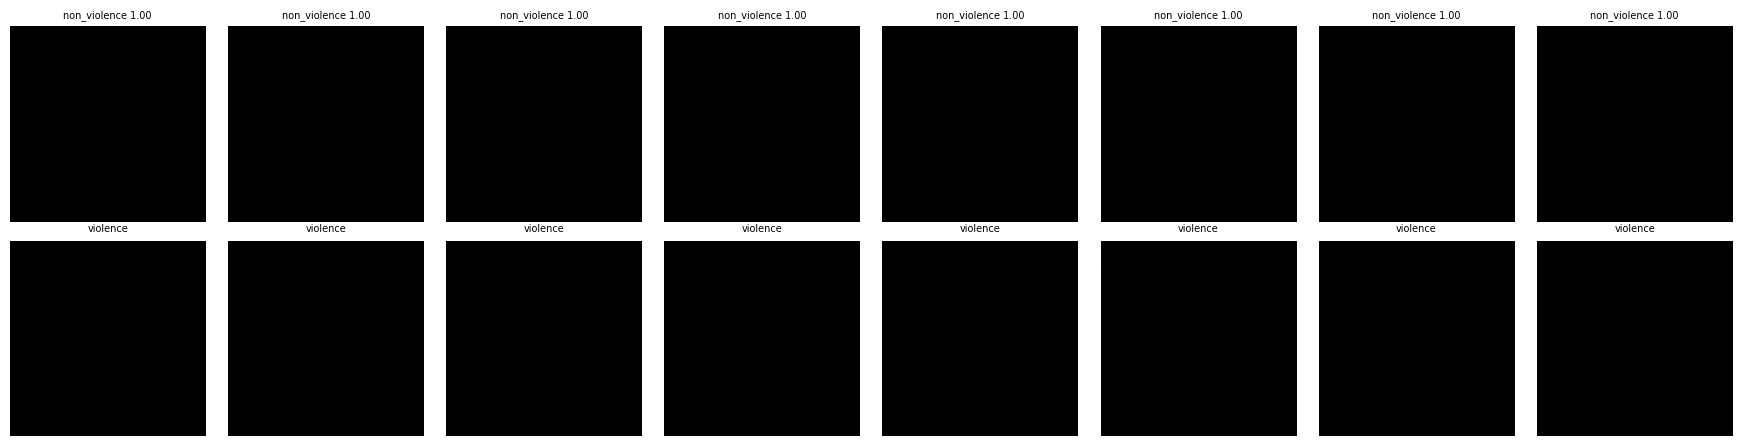

brillo:   0%|          | 0/11073 [00:00<?, ?it/s]

Fotogramas oscuros: 46 {'non_violence': 37, 'violence': 9}
Total eliminadas: 58 {'non_violence': 43, 'violence': 15}
Imágenes restantes: 11015


In [40]:
m_nv = (df["clase"] == "non_violence").values
S_cruzada = EMB[m_nv] @ EMB[~m_nv].T
i_nv, i_v = np.where(S_cruzada >= 0.95)
idx_nv, idx_v = np.where(m_nv)[0][i_nv], np.where(~m_nv)[0][i_v]
print(f"Pares duplicados entre clases: {len(i_nv)} | imágenes involucradas: {len(set(idx_nv)) + len(set(idx_v))}")

n_mostrar = min(8, len(i_nv))
if n_mostrar:
    fig, axes = plt.subplots(2, n_mostrar, figsize=(2.2 * n_mostrar, 4.5), squeeze=False)
    for c in range(n_mostrar):
        axes[0, c].imshow(Image.open(df.iloc[idx_nv[c]]["ruta"]))
        axes[0, c].set_title(f"non_violence {S_cruzada[i_nv[c], i_v[c]]:.2f}", fontsize=7)
        axes[1, c].imshow(Image.open(df.iloc[idx_v[c]]["ruta"]))
        axes[1, c].set_title("violence", fontsize=7)
        for a in axes[:, c]:
            a.axis("off")
    plt.tight_layout()
    plt.show()

def brillo_medio(ruta):
    return np.asarray(Image.open(ruta).convert("L").resize((64, 64))).mean()

df["brillo"] = [brillo_medio(r) for r in tqdm(df["ruta"], desc="brillo")]
oscuras = df["brillo"] < 15

eliminar = np.zeros(len(df), dtype=bool)
eliminar[np.union1d(idx_nv, idx_v)] = True
eliminar |= oscuras.values

print("Fotogramas oscuros:", oscuras.sum(), df[oscuras]["clase"].value_counts().to_dict())
print("Total eliminadas:", eliminar.sum(), df[eliminar]["clase"].value_counts().to_dict())

df = df[~eliminar].reset_index(drop=True)
EMB = EMB[~eliminar]
print("Imágenes restantes:", len(df))

## 8. Agrupación por componentes conexas

Conectamos las imágenes con similitud ≥ τ [1] y tomamos cada componente conexa como un grupo. Probamos varios valores de τ.

,tau,grupos,singletons,mayor,mayor_pct,grupos_dos_clases
0,0.850000,7147,6139,149,1.4%,2
1,0.800000,5030,3793,183,1.7%,14
2,0.780000,4098,2911,188,1.7%,17
3,0.760000,3057,2036,372,3.4%,10
4,0.750000,2542,1654,1378,12.5%,11
5,0.740000,2011,1308,2921,26.5%,14
6,0.720000,1184,750,6731,61.1%,8
7,0.700000,660,417,8737,79.3%,6
8,0.650000,113,75,10704,97.2%,2


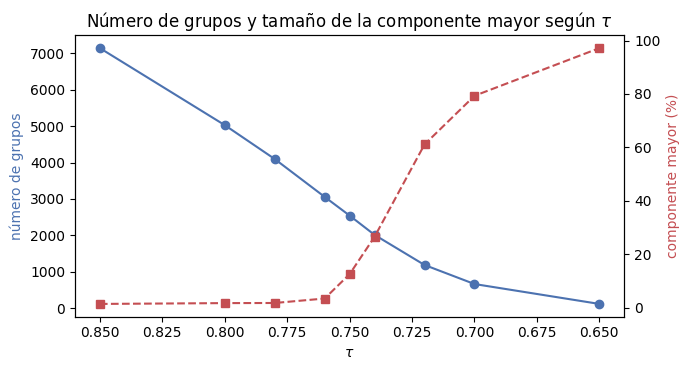

In [41]:
def grupos_para(tau, emb=None, bloque=2000):
    emb = EMB if emb is None else emb
    filas, cols = [], []
    for s in range(0, len(emb), bloque):
        r, c = np.where(emb[s:s + bloque] @ emb.T >= tau)
        filas.append(r + s)
        cols.append(c)
    filas, cols = np.concatenate(filas), np.concatenate(cols)
    A = csr_matrix((np.ones(len(filas), dtype=bool), (filas, cols)), shape=(len(emb), len(emb)))
    return connected_components(A, directed=False)[1]

barrido = []
for tau in [0.85, 0.80, 0.78, 0.76, 0.75, 0.74, 0.72, 0.70, 0.65]:
    etiquetas = grupos_para(tau)
    tam = pd.Series(etiquetas).value_counts()
    barrido.append({"tau": tau, "grupos": len(tam), "singletons": int((tam == 1).sum()),
                    "mayor": int(tam.iloc[0]), "mayor_pct": tam.iloc[0] / len(df),
                    "grupos_dos_clases": int(df.groupby(etiquetas)["clase"].nunique().gt(1).sum())})
barrido = pd.DataFrame(barrido)
display(barrido.style.format({"mayor_pct": "{:.1%}"}))

fig, ax1 = plt.subplots(figsize=(7, 3.8))
ax1.plot(barrido["tau"], barrido["grupos"], "o-", color="#4C72B0")
ax1.set_xlabel(r"$\tau$")
ax1.set_ylabel("número de grupos", color="#4C72B0")
ax1.invert_xaxis()
ax2 = ax1.twinx()
ax2.plot(barrido["tau"], barrido["mayor_pct"] * 100, "s--", color="#C44E52")
ax2.set_ylabel("componente mayor (%)", color="#C44E52")
ax1.set_title(r"Número de grupos y tamaño de la componente mayor según $\tau$")
plt.tight_layout()
plt.show()

**Elección de τ**

| τ | grupos | componente mayor |
|---|---|---|
| 0.76 | 3,057 | 3.4 % |
| 0.75 | 2,542 | 12.5 % |
| 0.74 | 2,011 | 26.5 % |
| 0.70 | 660 | 79.3 % |

Elegimos τ = 0.75, el valor más bajo antes de que la componente mayor crezca de golpe.

## 9. Partición en entrenamiento y validación

Partición 85/15 por grupos con `StratifiedGroupKFold`. La componente mayor va completa a entrenamiento. Elegimos la semilla con la proporción de clases más parecida entre los dos subconjuntos.

In [42]:
TAU = 0.75
df["grupo"] = grupos_para(TAU)
tam = df["grupo"].value_counts()
grupo_mayor = tam.index[0]
print(f"{len(tam)} grupos | componente mayor: {tam.iloc[0]} imágenes ({tam.iloc[0] / len(df):.1%}), "
      f"{df[df['grupo'] == grupo_mayor]['clase'].value_counts().to_dict()}")

es_violencia = (df["clase"] == "violence").values
p_global = es_violencia.mean()
resto = df[df["grupo"] != grupo_mayor]

mejor = None
for semilla in range(30):
    sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=semilla)
    for f, (_, idx_val) in enumerate(sgkf.split(resto, resto["clase"], resto["grupo"])):
        split = np.full(len(df), "train", dtype=object)
        split[resto.index[idx_val]] = "val"
        desviacion = max(abs(es_violencia[split == s].mean() - p_global) for s in ("train", "val"))
        if mejor is None or desviacion < mejor[0]:
            mejor = (desviacion, semilla, f, split)

desviacion, semilla, f, split = mejor
df["split"] = split
print(f"Semilla {semilla}, fold de validación {f}, desviación máxima {desviacion:.3f}\n")

tabla = pd.crosstab(df["split"], df["clase"], margins=True)
tabla["% del total"] = (tabla["All"] / len(df) * 100).round(1)
tabla["% violence"] = (tabla["violence"] / tabla["All"] * 100).round(1)
display(tabla.loc[["train", "val", "All"]])

comunes = set(df.loc[df["split"] == "train", "grupo"]) & set(df.loc[df["split"] == "val", "grupo"])
assert not comunes, "grupos compartidos entre entrenamiento y validación"
print("Ningún grupo aparece en ambos subconjuntos.")

2542 grupos | componente mayor: 1378 imágenes (12.5%), {'violence': 1378}
Semilla 15, fold de validación 2, desviación máxima 0.000



clase,non_violence,violence,All,% del total,% violence
split,,,,,
train,4500,5054,9554,86.7,52.9
val,688,773,1461,13.3,52.9
All,5188,5827,11015,100.0,52.9


Ningún grupo aparece en ambos subconjuntos.


Pares validación vs. entrenamiento más similares: similitud máxima media 0.698 | máxima 0.750


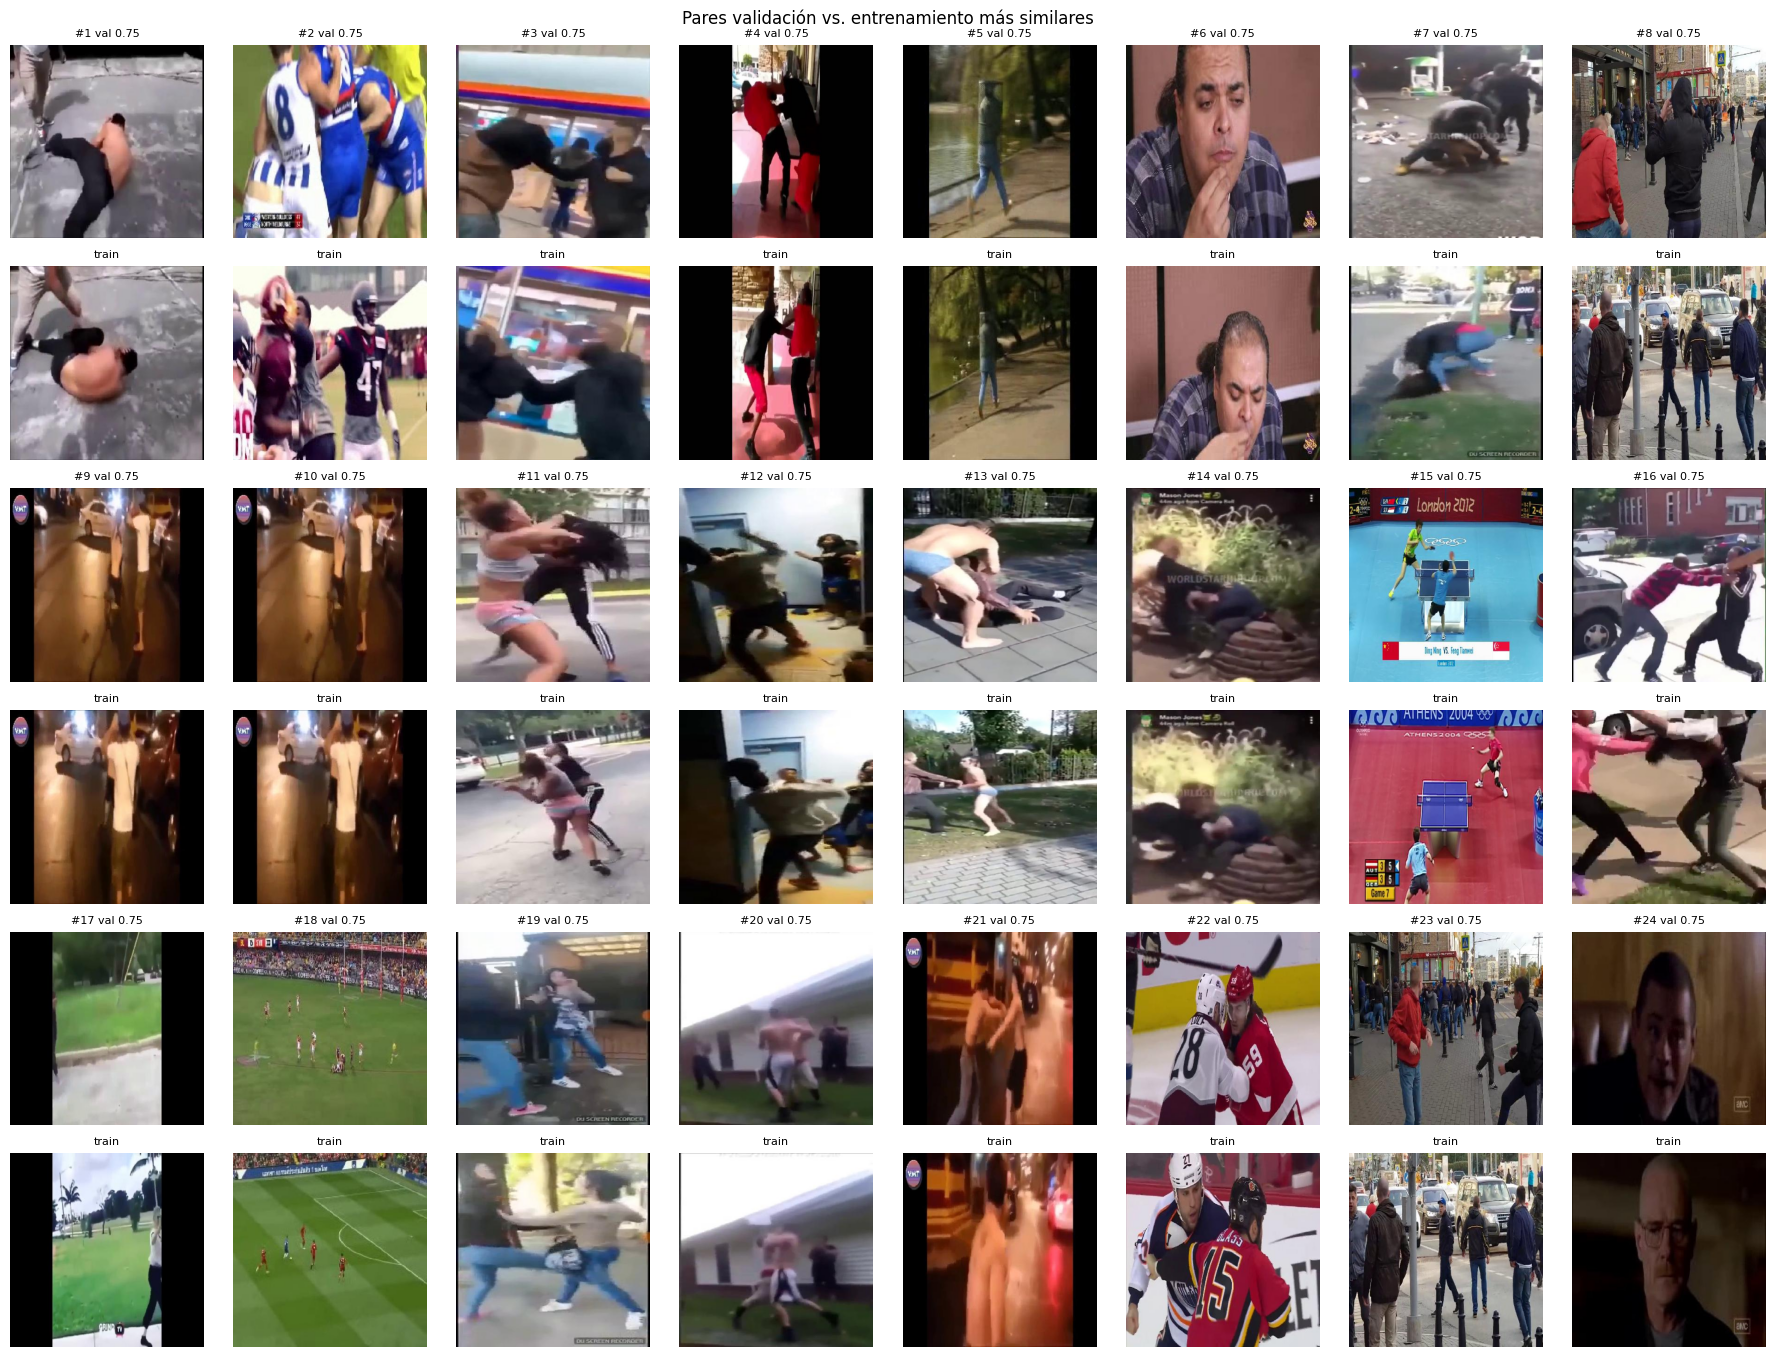

In [43]:
idx_train = np.where(df["split"] == "train")[0]
idx_val = np.where(df["split"] == "val")[0]
sim_val = mostrar_pares(idx_val, idx_train, n=24,
                        titulo="Pares validación vs. entrenamiento más similares", etiqueta="val")

**Resultado**

Algunos pares con similitud cercana a 0.75 siguen siendo del mismo video, así que la validación puede salir optimista. Por eso la prueba se hace con otro dataset.

Guardamos la partición en `splits.csv`.

In [44]:
df[["archivo", "clase", "grupo", "split"]].to_csv(os.path.join(SALIDA, "splits.csv"), index=False)
print("Guardado:", os.path.join(SALIDA, "splits.csv"))

Guardado: /content/drive/MyDrive/violence-detection/splits.csv


## 10. Conjunto de prueba

Dataset de Bianculli et al. [5]: 350 clips (230 violentos y 120 no violentos), grabados con dos cámaras por escena. Extraemos 8 fotogramas por video y los redimensionamos a 416 × 416.

In [45]:
N_FRAMES = 8
zip_frames = os.path.join(SALIDA, "bianculli_frames.zip")
csv_frames = os.path.join(SALIDA, "bianculli_frames.csv")

if os.path.exists(zip_frames) and os.path.exists(csv_frames):
    shutil.unpack_archive(zip_frames, FRAMES_DIR)
    df_ext = pd.read_csv(csv_frames)
    print("Fotogramas cargados desde", zip_frames)
else:
    if not os.path.exists(EXT_REPO):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/airtlab/A-Dataset-for-Automatic-Violence-Detection-in-Videos.git",
                        EXT_REPO], check=True)
    EXT_DIR = os.path.join(EXT_REPO, "violence-detection-dataset")

    mapa_clase = {"violent": "violence", "non-violent": "non_violence"}
    videos = [(v, carpeta, clase, cam)
              for carpeta, clase in mapa_clase.items()
              for cam in ["cam1", "cam2"]
              for v in sorted(glob.glob(os.path.join(EXT_DIR, carpeta, cam, "*.mp4")))]
    print("Videos encontrados:", len(videos))

    registros_ext = []
    for video, carpeta, clase, cam in tqdm(videos, desc="extracción"):
        cap = cv2.VideoCapture(video)
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        objetivos = set(np.linspace(0, total - 1, N_FRAMES + 2, dtype=int)[1:-1])
        nombre = os.path.splitext(os.path.basename(video))[0]
        k = 0
        for f_idx in range(total):
            if not cap.grab():
                break
            if f_idx not in objetivos:
                continue
            ok, frame = cap.retrieve()
            if not ok:
                continue
            frame = cv2.resize(frame, (416, 416), interpolation=cv2.INTER_AREA)
            archivo = f"{clase}/{cam}_{nombre}_{k}.jpg"
            os.makedirs(os.path.join(FRAMES_DIR, clase), exist_ok=True)
            cv2.imwrite(os.path.join(FRAMES_DIR, archivo), frame)
            registros_ext.append({"archivo": archivo, "clase": clase, "cam": cam,
                                  "video": f"{carpeta}/{cam}/{nombre}", "escena": f"{carpeta}/{nombre}"})
            k += 1
            if k == N_FRAMES:
                break
        cap.release()

    df_ext = pd.DataFrame(registros_ext)
    df_ext.to_csv(csv_frames, index=False)
    shutil.make_archive(zip_frames[:-4], "zip", FRAMES_DIR)
    print("Guardado:", zip_frames)

display(df_ext.groupby(["clase", "cam"]).agg(videos=("video", "nunique"), fotogramas=("archivo", "size")))

Fotogramas cargados desde /content/drive/MyDrive/violence-detection/bianculli_frames.zip


videos  fotogramas
clase        cam                     
non_violence cam1      60         480
             cam2      60         480
violence     cam1     115         920
             cam2     115         920

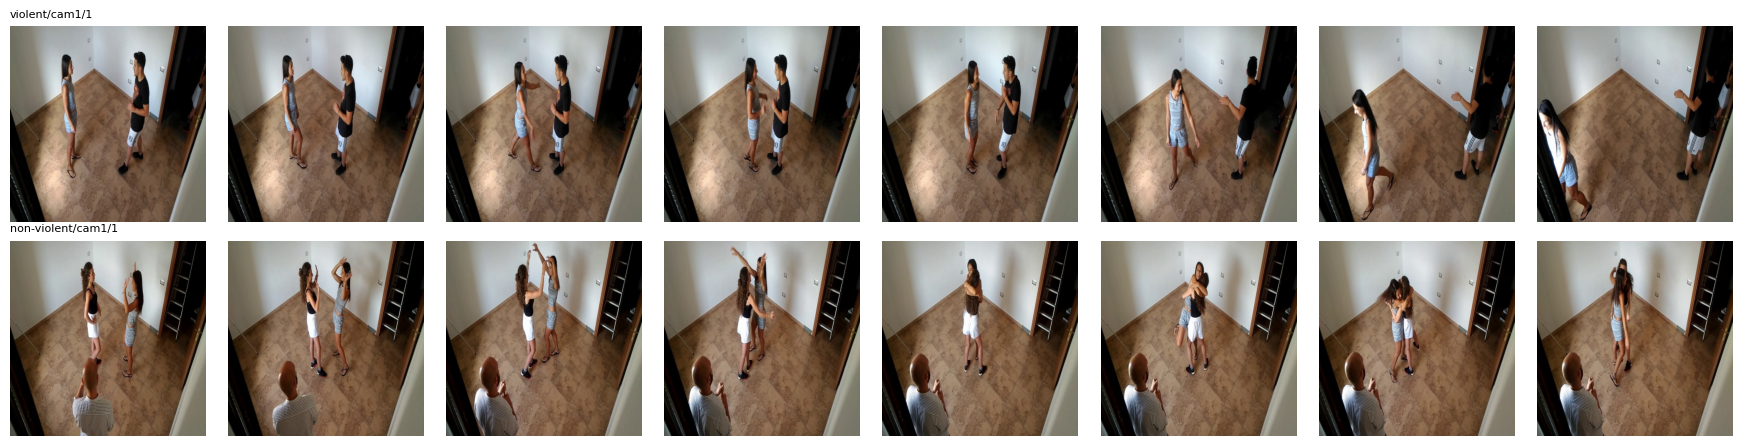

In [46]:
fig, axes = plt.subplots(2, N_FRAMES, figsize=(2.2 * N_FRAMES, 4.5))
for r, clase in enumerate(["violence", "non_violence"]):
    video = df_ext[df_ext["clase"] == clase]["video"].iloc[0]
    for c, archivo in enumerate(df_ext[df_ext["video"] == video]["archivo"]):
        axes[r, c].imshow(Image.open(os.path.join(FRAMES_DIR, archivo)))
        axes[r, c].axis("off")
    axes[r, 0].set_title(video, fontsize=8, loc="left")
plt.tight_layout()
plt.show()

Las escenas son en interiores y con la cámara en alto, a diferencia de los datos de entrenamiento.